Objetivo: fixando nível de irrigação baixa. queremos ver se biofertilizante faz efeito na produtividade de milho. Além disso comparar métodos: jeito frequentista e teste de permutação, e bootstrap.

---

# 1. Descrição da base de dados e de cada variável.

## Descição inicial da base de dados

Reutilizamos a base de dados "produtividade_milho.csv" disponibilizada pelo professor, que está em formato longo e contém 480 linhas: 120 blocos agrícolas (unidades experimentais), cada um observado sob os 4 tratamentos de um fatorial 2x2 (irrigação x biofertilizante, dois níveis pra cada). 

Não temos informações sobre o local de coleta...

As variáveis são:

### Variável quantitativa (resposta):

- "produtividade_sacas_ha": produtividade de milho, em sacas por hectare (contínua, numérica). Na base completa varia de 36,88 a 88,86 sacas/ha.


---

### Variáveis categóricas:

- "bloco": identificador da unidade experimental (Bloco_001, ..., Bloco_120). Não é uma variável de interesse em si, mas é essencial: é ela que diz quais observações vieram do **mesmo** bloco, ou seja, quais observações estão pareadas;
- "irrigacao": fator com 2 níveis (*reduzida* / *adequada*);
- "biofertilizante": fator com 2 níveis (*sem_biofertilizante* / *com_biofertilizante*);
- "tratamento": rótulo da combinação irrigação x biofertilizante (4 níveis). É redundante com as duas anteriores, só junta as duas em uma variável.


---


### Variáveis usadas neste trabalho: 

Supondo que estamos numa situação em que as grande empresas de tecnologia estão gastando muita água para treinar certos modelos de linguagem, deixando os recursos hídricos caros, e nossos amigos agricultores querem ver como que a produtividade do milho reage a biofertilizante com irrigação reduzida.

Logo o nosso *objetivo* é estudar o *efeito do biofertilizante* **fixando a irrigação reduzida**, vamos trabalhar apenas com as 240 linhas em que irrigacao == "reduzida". Nesse recorte a irrigação vira uma constante, e sobram:

- a resposta "produtividade_sacas_ha";
- o fator de interesse "biofertilizante" (sem / com);
- o identificador "bloco", que liga as duas medidas de um mesmo bloco.

Chamando de $X_{1j}$ a produtividade do bloco $j$ sob irrigação reduzida **sem** biofertilizante e de $X_{2j}$ a produtividade do mesmo bloco sob irrigação reduzida **com** biofertilizante, cada bloco fornece o par $(X_{1j}, X_{2j})$, $j = 1, \dots, 120$, e a diferença

$$Z_j = X_{2j} - X_{1j},$$

que mede o ganho (ou perda) de produtividade que o biofertilizante trouxe naquele bloco. Daí toda a análise inferencial será feita sobre os $Z_j$.

---

# 2. Tabelas de dados:



No trabalho que fizemos em Estatística Multivariada 1, conferimos que cada bloco aparece exatamente uma vez em cada tratamento (base completa) e que, no recorte com irrigação reduzida, cada bloco tem exatamente uma observação sem e uma com biofertilizante. 

(Se isso não valesse, o pareamento não estaria bem definido.)

In [5]:
dados <- read.csv("produtividade_milho.csv")

dados$irrigacao <- factor(dados$irrigacao, levels = c("reduzida", "adequada"))
dados$biofertilizante <- factor(dados$biofertilizante, levels = c("sem_biofertilizante", "com_biofertilizante"))
dados$tratamento <- factor(dados$tratamento, levels = c("reduzida_sem_biofertilizante",
                                                          "reduzida_com_biofertilizante",
                                                          "adequada_sem_biofertilizante",
                                                          "adequada_com_biofertilizante"))

head(dados)

,bloco,irrigacao,biofertilizante,tratamento,produtividade_sacas_ha
,<chr>,<fct>,<fct>,<fct>,<dbl>
1,Bloco_001,reduzida,sem_biofertilizante,reduzida_sem_biofertilizante,57.59
2,Bloco_001,reduzida,com_biofertilizante,reduzida_com_biofertilizante,65.02
3,Bloco_001,adequada,sem_biofertilizante,adequada_sem_biofertilizante,66.26
4,Bloco_001,adequada,com_biofertilizante,adequada_com_biofertilizante,70.77
5,Bloco_002,reduzida,sem_biofertilizante,reduzida_sem_biofertilizante,44.32
6,Bloco_002,reduzida,com_biofertilizante,reduzida_com_biofertilizante,42.57


In [6]:
library(tidyr)

red <- droplevels(subset(dados, irrigacao == "reduzida")) # só os dados com irrigação reduzida

largo <- pivot_wider(red, # formato largo, já que nos dados originais cada linha é uma observação
                     id_cols = bloco,
                     names_from = biofertilizante,
                     values_from = produtividade_sacas_ha)
                     
largo <- as.data.frame(largo) # deixar a tabela em formato data.frame
names(largo) <- c("bloco", "sem", "com")

largo$Z <- largo$com - largo$sem
Z <- largo$Z
n <- length(Z)

head(largo)
n

,bloco,sem,com,Z
,<chr>,<dbl>,<dbl>,<dbl>
1,Bloco_001,57.59,65.02,7.43
2,Bloco_002,44.32,42.57,-1.75
3,Bloco_003,59.11,60.49,1.38
4,Bloco_004,36.88,51.03,14.15
5,Bloco_005,63.70,72.65,8.95
6,Bloco_006,52.31,57.89,5.58


[1] 120

In [7]:
# código do trabalho passado
# base completa
table(dados$irrigacao, dados$biofertilizante)

# fixando irrigação reduzida
table(red$biofertilizante)

          
           sem_biofertilizante com_biofertilizante
  reduzida                 120                 120
  adequada                 120                 120


sem_biofertilizante com_biofertilizante 
                120                 120 

---

In [8]:
summary(dados)

    bloco              irrigacao              biofertilizante
 Length:480         reduzida:240   sem_biofertilizante:240   
 Class :character   adequada:240   com_biofertilizante:240   
 Mode  :character                                            
                                                             
                                                             
                                                             
                        tratamento  produtividade_sacas_ha
 reduzida_sem_biofertilizante:120   Min.   :36.88         
 reduzida_com_biofertilizante:120   1st Qu.:53.73         
 adequada_sem_biofertilizante:120   Median :60.52         
 adequada_com_biofertilizante:120   Mean   :60.98         
                                    3rd Qu.:67.84         
                                    Max.   :88.86         

---

# 3. Descrição do problema

No trabalho de Mult 1 vimos que, pelo gráfico de interação, tanto a irrigação quanto o biofertilizante parecem aumentar a produtividade, e que o efeito de um fator parece depender do nível do outro (linhas não paralelas). Por causa dessa possível interação, e da situação suposta dita na primeira seção, não faz muito sentido falar de "um único efeito do biofertilizante": ele pode ser diferente em cada nível de irrigação. Por isso, aqui **fixamos a irrigação reduzida**, que é a situação mais desfavorável para os produtores de milho, e perguntamos:

> **Sob irrigação reduzida, o uso de biofertilizante altera a produtividade média de milho?**

---

### Estrutura dos dados.

Reforçando mais uma vez: cada bloco recebeu os dois níveis de biofertilizante (em subparcelas diferentes). Então as duas amostras **não são independentes**: são medidas repetidas na mesma unidade experimental. O problema se reduz a um problema de **uma amostra** sobre as diferenças $Z_1, \dots, Z_{120}$, cuja média populacional chamamos de

$$\mu_Z = E(Z_j) = E(X_{2j}) - E(X_{1j}) = \mu_2 - \mu_1.$$

Se o biofertilizante não tem efeito, $\mu_Z = 0$. A estatística natural para estimar $\mu_Z$ é a média amostral das diferenças, $\bar{Z}$.

---

**Comparação de métodos.** Além de responder à pergunta, o trabalho compara três formas de fazer inferência sobre $\mu_Z$:

1. **Frequentista clássico (paramétrico):** teste t pareado, que usa a distribuição t de Student para a estatística $T = \bar Z / (S_Z/\sqrt{n})$, assumindo normalidade de $Z$ (ou $n$ grande).

2. **Teste de permutação:** sob a hipótese de que o biofertilizante não tem efeito, os rótulos "sem" e "com" dentro de cada bloco são intercambiáveis. Trocar os rótulos de um bloco equivale a trocar o sinal de $Z_j$. Gerando muitas trocas aleatórias de sinais, construímos a distribuição de $\bar Z$ sob $H_0$ **sem supor normalidade**.

3. **Bootstrap:** reamostramos os blocos (com reposição) para aproximar a distribuição amostral de $\bar Z$ diretamente a partir dos dados. Com isso obtemos um intervalo de confiança (percentil) e, centrando os dados em zero, também um p-valor.

No final comparamos estimativas, intervalos de confiança e p-valores dos três métodos e discutimos quando cada um é mais adequado.

---

# 4. Análise Descritiva

### 4.1 Medidas de resumo

In [9]:
resumo <- function(x) { # funçãozinha para calcular as estatísticas descritivas com nomes em ptbr
  c(n        = length(x),
    media    = mean(x),
    dp       = sd(x),
    CV_pct   = 100 * sd(x) / mean(x),
    minimo   = min(x),
    Q1       = unname(quantile(x, 0.25)),
    mediana  = median(x),
    Q3       = unname(quantile(x, 0.75)),
    maximo   = max(x))
}

In [10]:
tabela_resumo <- rbind("Sem biofertilizante (X1)" = resumo(largo$sem),
                       "Com biofertilizante (X2)" = resumo(largo$com),
                       "Diferença Z = X2 - X1"    = resumo(largo$Z))
round(tabela_resumo, 3)

,n,media,dp,CV_pct,minimo,Q1,mediana,Q3,maximo
Sem biofertilizante (X1),120,52.170,6.284,12.046,36.88,48.478,52.290,55.995,68.45
Com biofertilizante (X2),120,57.817,6.902,11.938,42.57,52.798,57.870,62.565,74.96
Diferença Z = X2 - X1,120,5.648,4.765,84.371,-5.14,2.035,5.615,8.935,19.11


### Interpretação dessa saida em R:

Na irrigação reduzida, estima-se que a produtividade média passa de cerca de 52,17 sacas/ha (sem biofertilizante) para 57,82 sacas/ha (com biofertilizante), um ganho médio de aproximadamente 5,65 sacas/ha. A mediana das diferenças (≈ 5,6) é praticamente igual à média, o que é um indício de que a distribuição de $Z$ é aproximadamente simétrica.

Um ponto importante: o desvio padrão de $Z$ (≈ 4,76) é **menor** do que o desvio padrão de cada grupo separado (≈ 6,3 e 6,9). 

Isso acontece porque blocos que produzem muito sem o biofertilizante também tendem a produzir muito com ele (os blocos diferem em solo, relevo etc.), e ao fazer a diferença dentro do bloco essa variação entre blocos "se cancela". 

A tabela abaixo mostra isso pela matriz de covariâncias e pela correlação entre $X_1$ e $X_2$.

In [11]:
S <- cov(largo[, c("sem", "com")])
round(S, 3)

r_12 <- cor(largo$sem, largo$com)
cat(sprintf("Correlação entre X1 e X2: %.3f\n", r_12))

# Var(Z) = Var(X1) + Var(X2) - 2 Cov(X1, X2)
cat(sprintf("Var(X1) + Var(X2) - 2Cov(X1,X2) = %.3f   |   var(Z) calculada direto = %.3f\n",
            S[1,1] + S[2,2] - 2 * S[1,2], var(largo$Z)))

,sem,com
sem,39.492,32.215
com,32.215,47.642


Correlação entre X1 e X2: 0.743
Var(X1) + Var(X2) - 2Cov(X1,X2) = 22.704   |   var(Z) calculada direto = 22.704


A correlação entre as produtividades sem e com biofertilizante dentro do mesmo bloco é alta (≈ 0,74). Pela relação $Var(Z) = Var(X_1) + Var(X_2) - 2\,Cov(X_1, X_2)$, essa covariância positiva diminui bastante a variância da diferença. É por isso que a análise **pareada** (usando $Z_j$) é a correta aqui, e também a mais eficiente.

In [12]:
sinal <- cut(largo$Z, breaks = c(-Inf, -1e-12, 1e-12, Inf),
             labels = c("Z < 0 (piorou)", "Z = 0", "Z > 0 (melhorou)"))
tab_sinal <- table(sinal)
cbind(Frequencia = tab_sinal,
      Proporcao  = round(prop.table(tab_sinal), 3))

,Frequencia,Proporcao
Z < 0 (piorou),16,0.133
Z = 0,0,0.000
Z > 0 (melhorou),104,0.867


Em 104 dos 120 blocos (≈ 86,7%) a produtividade foi maior com biofertilizante; em apenas 16 blocos (≈ 13,3%) foi menor. Nenhum bloco teve diferença exatamente nula.

---

### 4.2 Distribuição da produtividade em cada grupo

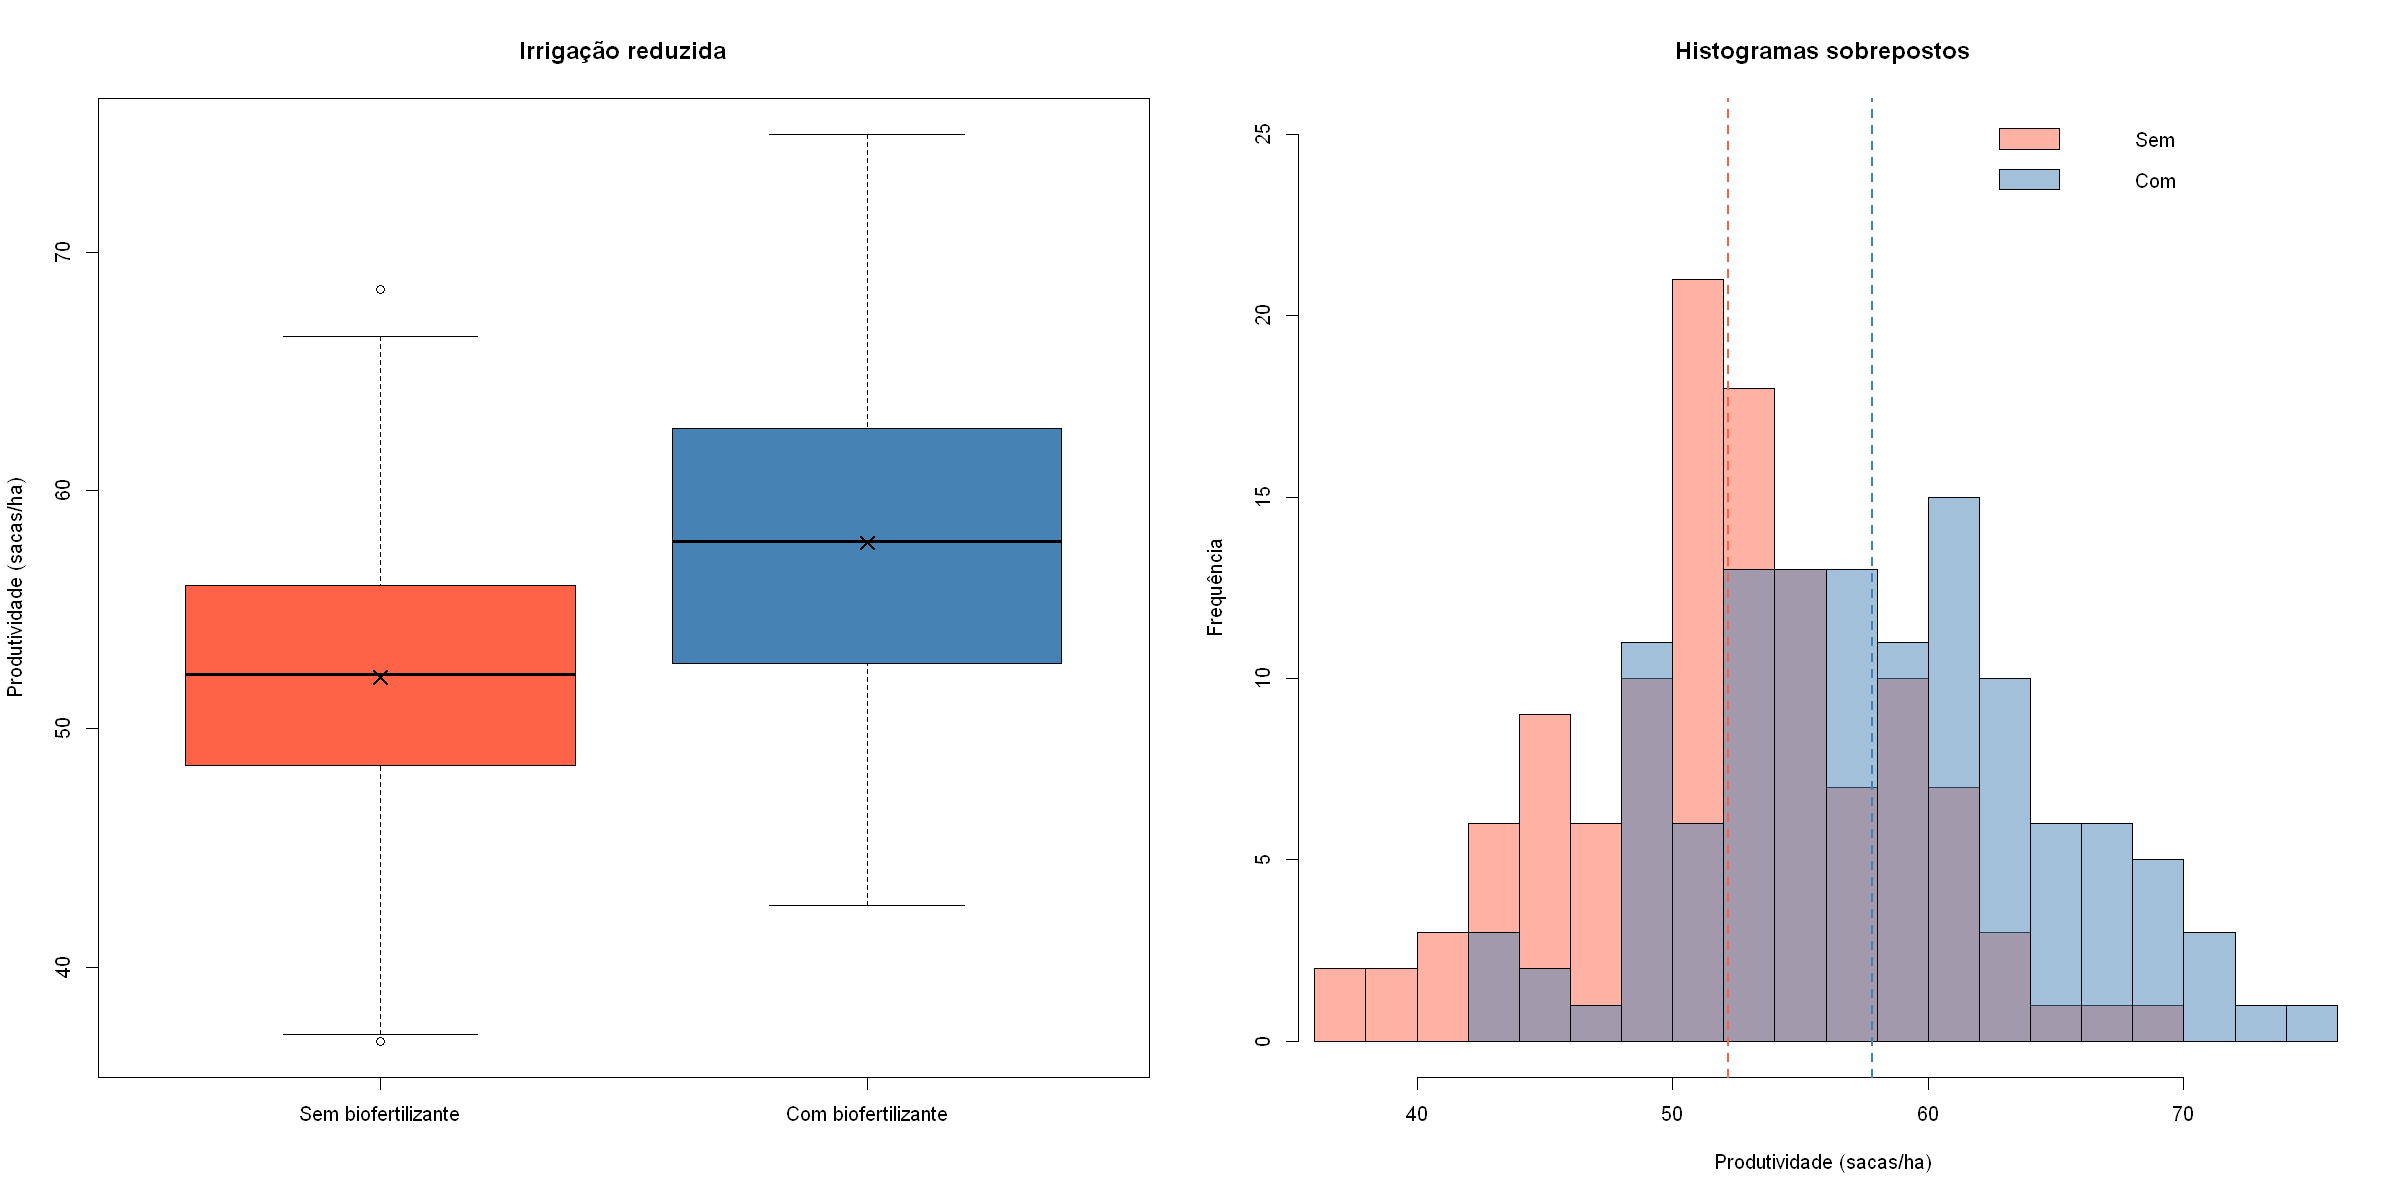

In [13]:
options(repr.plot.width = 20, repr.plot.height = 10)
par(mfrow = c(1, 2))

boxplot(largo$sem, largo$com,
        names = c("Sem biofertilizante", "Com biofertilizante"),
        col = c("tomato", "steelblue"),
        ylab = "Produtividade (sacas/ha)",
        main = "Irrigação reduzida")

points(c(1, 2), c(mean(largo$sem), mean(largo$com)), pch = 4, cex = 1.5, lwd = 2)
######################################
hist(largo$sem, breaks = 15, col = adjustcolor("tomato", 0.5), border = "black",
     xlim = range(c(largo$sem, largo$com)), ylim = c(0, 25),
     xlab = "Produtividade (sacas/ha)", ylab = "Frequência",
     main = "Histogramas sobrepostos")

hist(largo$com, breaks = 15, col = adjustcolor("steelblue", 0.5), border = "black", add = TRUE)

abline(v = c(mean(largo$sem), mean(largo$com)), col = c("tomato", "steelblue"), lwd = 2, lty = 2)

legend("topright", legend = c("Sem", "Com"), fill = adjustcolor(c("tomato", "steelblue"), 0.5), bty = "n")

par(mfrow = c(1, 1))

Os dois grupos têm dispersão parecida e formatos aproximadamente simétricos, e a distribuição "com biofertilizante" aparece deslocada para cima (o × marca a média). Porém, olhando os grupos separadamente, há bastante sobreposição entre as caixas. Esse gráfico **ignora o pareamento**: ele mistura a variação entre blocos com o efeito do biofertilizante. Os gráficos seguintes levam o pareamento em conta.

---



### 4.3 Perfis individuais dos blocos

Reutilizando código do trabalho passado, mas agora com a base de dados de irrigação reduzida:

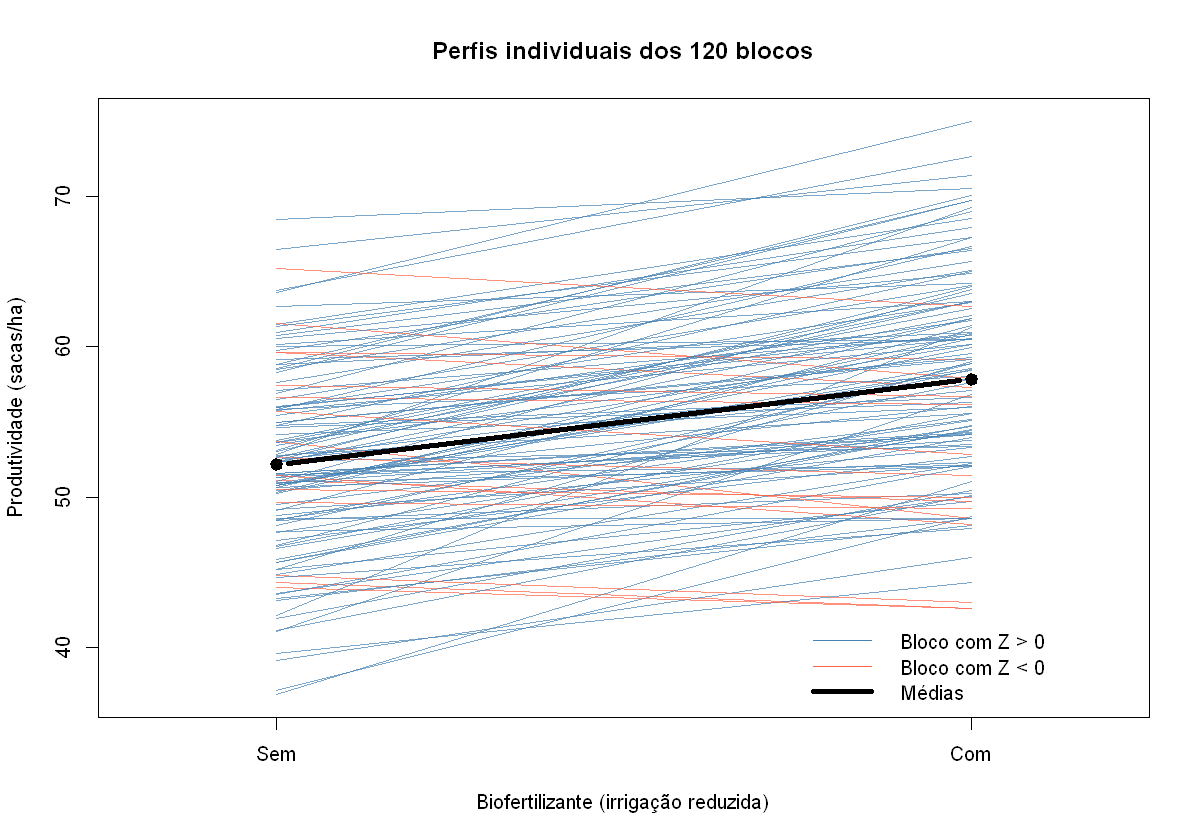

In [14]:
options(repr.plot.width = 10, repr.plot.height = 7)

cor_perfil <- ifelse(largo$Z > 0, "steelblue", "tomato")

plot(NA, xlim = c(0.8, 2.2), ylim = range(c(largo$sem, largo$com)),
     xaxt = "n", xlab = "Biofertilizante (irrigação reduzida)", ylab = "Produtividade (sacas/ha)",
     main = "Perfis individuais dos 120 blocos")
axis(1, at = c(1, 2), labels = c("Sem", "Com"))

for (j in 1:n) {
  lines(c(1, 2), c(largo$sem[j], largo$com[j]), col = adjustcolor(cor_perfil[j], alpha.f = .7))
}
lines(c(1, 2), c(mean(largo$sem), mean(largo$com)), lwd = 4, type = "b", pch = 19)

legend("bottomright",
       legend = c("Bloco com Z > 0", "Bloco com Z < 0", "Médias"),
       col = c("steelblue", "tomato", "black"), lwd = c(1, 1, 4), bty = "n")

Cada linha é um bloco. A grande maioria das linhas (em azul) sobe ao passar de "sem" para "com" biofertilizante, e as poucas que descem (em vermelho) descem pouco. Também dá para ver que as linhas quase não se cruzam muito: blocos que estão "em cima" sem biofertilizante tendem a continuar "em cima" com ele. Isso é muito condizente com a correlação alta vista na seção 2.

---

### 4.4 Diagrama de dispersão $X_1$ vs $X_2$

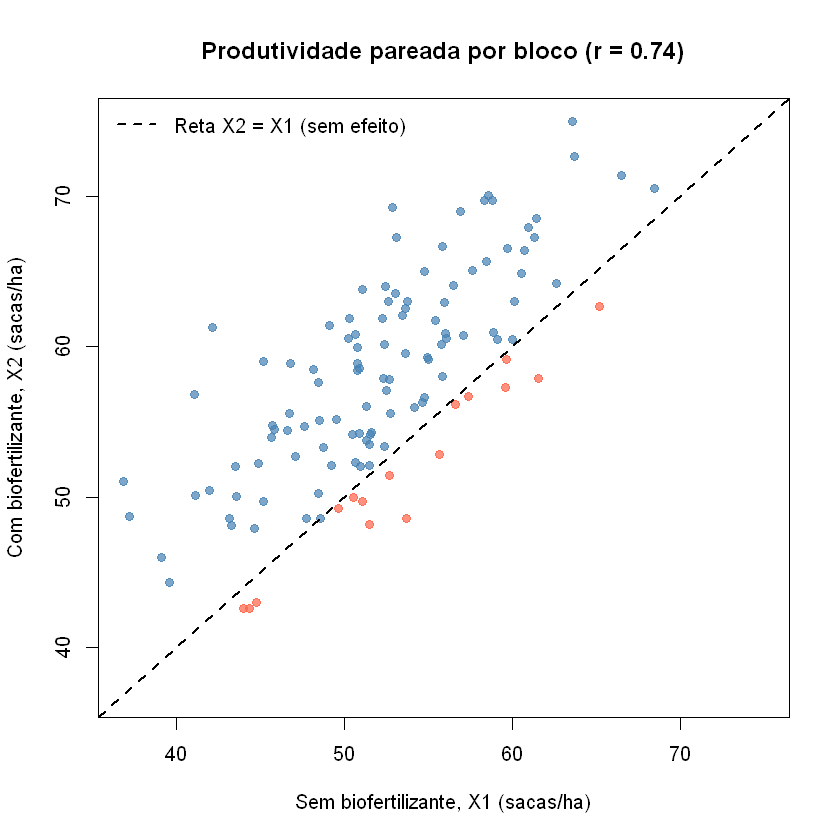

In [15]:
options(repr.plot.width = 7, repr.plot.height = 7)

lim <- range(c(largo$sem, largo$com))
plot(largo$sem, largo$com, pch = 19, col = adjustcolor(cor_perfil, .7),
     xlim = lim, ylim = lim,
     xlab = "Sem biofertilizante, X1 (sacas/ha)",
     ylab = "Com biofertilizante, X2 (sacas/ha)",
     main = sprintf("Produtividade pareada por bloco (r = %.2f)", r_12))
abline(0, 1, lty = 2, lwd = 2)
legend("topleft", legend = c("Reta X2 = X1 (sem efeito)"), lty = 2, lwd = 2, bty = "n")

A reta tracejada é $X_2 = X_1$, ou seja, a situação de "nenhum efeito". Pontos acima dela são blocos que melhoraram com o biofertilizante, ponto abaixo dela são os que pioaram. 

A nuvem está claramente deslocada para cima da reta e alinhada com ela (correlação ≈ 0,74), confirmando um ganho de produtividade com fertilizante nos blocos.

---

### 4.5 Distribuição das diferenças $Z_j$


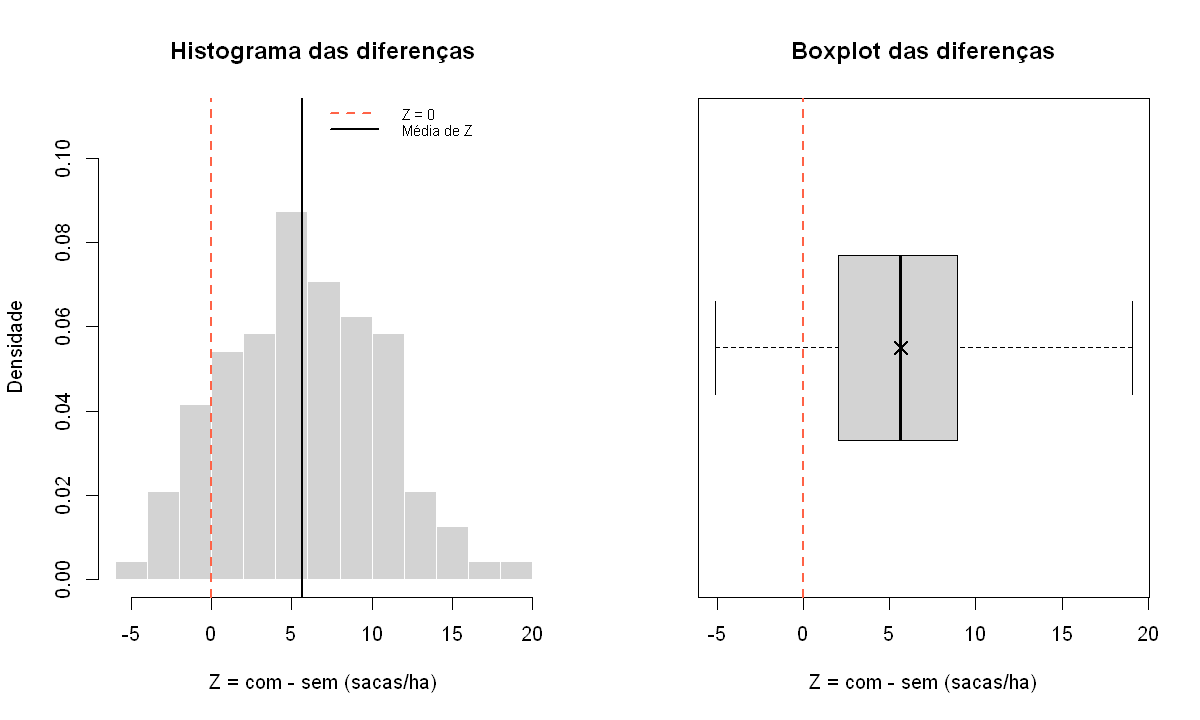

In [16]:
options(repr.plot.width = 10, repr.plot.height = 6)
par(mfrow = c(1, 2))

hist(Z, breaks = 15, freq = FALSE, col = "lightgray", border = "white", ylim = c(0, 0.11),
     xlab = "Z = com - sem (sacas/ha)", ylab = "Densidade",
     main = "Histograma das diferenças")
abline(v = 0, lty = 2, lwd = 2, col = "tomato")
abline(v = mean(Z), lwd = 2)
legend("topright", legend = c( "Z = 0", "Média de Z"),
       col = c( "tomato", "black"), lty = c(2, 1), lwd = 2, bty = "n", cex = 0.75)

boxplot(Z, horizontal = TRUE, col = "lightgray",
        xlab = "Z = com - sem (sacas/ha)", main = "Boxplot das diferenças")
abline(v = 0, lty = 2, lwd = 2, col = "tomato")
points(mean(Z), 1, pch = 4, cex = 1.5, lwd = 2)

par(mfrow = c(1, 1))

In [17]:
round(tabela_resumo[1:3, ], 3)


,n,media,dp,CV_pct,minimo,Q1,mediana,Q3,maximo
Sem biofertilizante (X1),120,52.170,6.284,12.046,36.88,48.478,52.290,55.995,68.45
Com biofertilizante (X2),120,57.817,6.902,11.938,42.57,52.798,57.870,62.565,74.96
Diferença Z = X2 - X1,120,5.648,4.765,84.371,-5.14,2.035,5.615,8.935,19.11


Interpretação:

- Média das diferenças: 5.647 sacas/ha; mediana: 5.615 sacas/ha.
- Desvio padrão das diferenças: 4.765 sacas/ha; erro padrão da média: 0.435 sacas/ha.
- 104 de 120 blocos (86.7%) tiveram Z > 0.

A média de Z está a 13.0 erros padrão de distância de zero, o que, descritivamente, já sugere fortemente que o biofertilizante aumenta a produtividade sob irrigação reduzida. Os testes formais vêm nas próximas seções.

---

# 5. Hipóteses a serem testadas

Seja $\mu_Z = \mu_2 - \mu_1$ a diferença entre a produtividade média **com** e **sem** biofertilizante, sob irrigação reduzida. A pergunta "o biofertilizante faz efeito?" corresponde a:

$$
\begin{cases}
H_0: \mu_Z = 0 \quad \text{(o biofertilizante não altera a produtividade média)}\\
H_1: \mu_Z \neq 0 \quad \text{(o biofertilizante altera a produtividade média)}
\end{cases}
$$

Usamos a alternativa **bilateral** porque, antes de ver os dados, não há garantia de que o efeito seja positivo (um biofertilizante pode, por exemplo, competir por água com a planta quando a irrigação é baixa). 

Fixamos um nível de significância de $\alpha = 0{,}05$.

Os três métodos no fundo testam a mesma pergunta, mas com suposições ligeiramente diferentes de $H_0$:

| Método | Estatística | Suposição de $H_0$ | Como obtém a distribuição sob $H_0$ |
|---|---|---|---|
| Teste t pareado | $T = \dfrac{\bar Z}{S_Z/\sqrt{n}}$ | $\mu_Z = 0$, com $Z_j \sim N(\mu_Z, \sigma_Z^2)$ | Teórica: $T \sim t_{n-1}$ |
| Permutação (troca de sinais) | $\bar Z$ | A distribuição de $Z_j$ é simétrica em torno de 0 (os rótulos "sem"/"com" são intercambiáveis dentro do bloco) | Empírica: trocando aleatoriamente o sinal de cada $Z_j$ |
| Bootstrap | $\bar Z$ | $\mu_Z = 0$ | Empírica: reamostrando $Z_j - \bar Z$ (dados centrados, para que $H_0$ valha) |

Além do teste, vamos construir **intervalos de confiança de 95% para $\mu_Z$** pelo método t e pelo bootstrap (percentil). Rejeitar $H_0$ a 5% equivale a o intervalo de 95% não conter o zero.





## 6. Suposições:

Note que os testes tem suposições diferentes:

**Teste t pareado** 

- **(Suposição 1, a mais forte) Normalidade das diferenças:** $Z_j \sim N(\mu_Z, \sigma_Z^2)$. Com $n = 120$, mesmo que $Z$ não seja exatamente normal, pelo Teorema Central do Limite $\bar Z$ é aproximadamente normal, então o teste é robusto a desvios moderados. O que pode atrapalhar são assimetria forte ou outliers.

---

**Teste de permutação (troca de sinais)**

- **(Suposição 2, mais fraca que a normalidade) Intercambiabilidade sob $H_0$:** se o biofertilizante não tem efeito, trocar os níveis "sem" e "com" dentro de um bloco não muda a distribuição conjunta do par. Isso implica que $Z_j$ tem distribuição **simétrica em torno de 0** sob $H_0$. No experimento, isso é garantido pela **aleatorização**: se a escolha da subparcela que recebeu o biofertilizante foi feita ao acaso, os rótulos são intercambiáveis sob $H_0$. Não precisa de normalidade.

Já vimos na seção de análise descritiva que a distribuição é aproximadamente simétrica.

---

**Bootstrap**
- **(Suposição 3, a mais fraca) A amostra representa bem a população:** o bootstrap usa a distribuição empírica dos $Z_j$ como substituta da distribuição verdadeira, então é preciso $n$ razoavelmente grande e amostra sem vícios.

---

Além disso, esses métodos exigem independência entre os blocos.

---


# 7. Verificação das suposições

### 7.1 Normalidade (do teste t):


	Shapiro-Wilk normality test

data:  Z
W = 0.99341, p-value = 0.8462


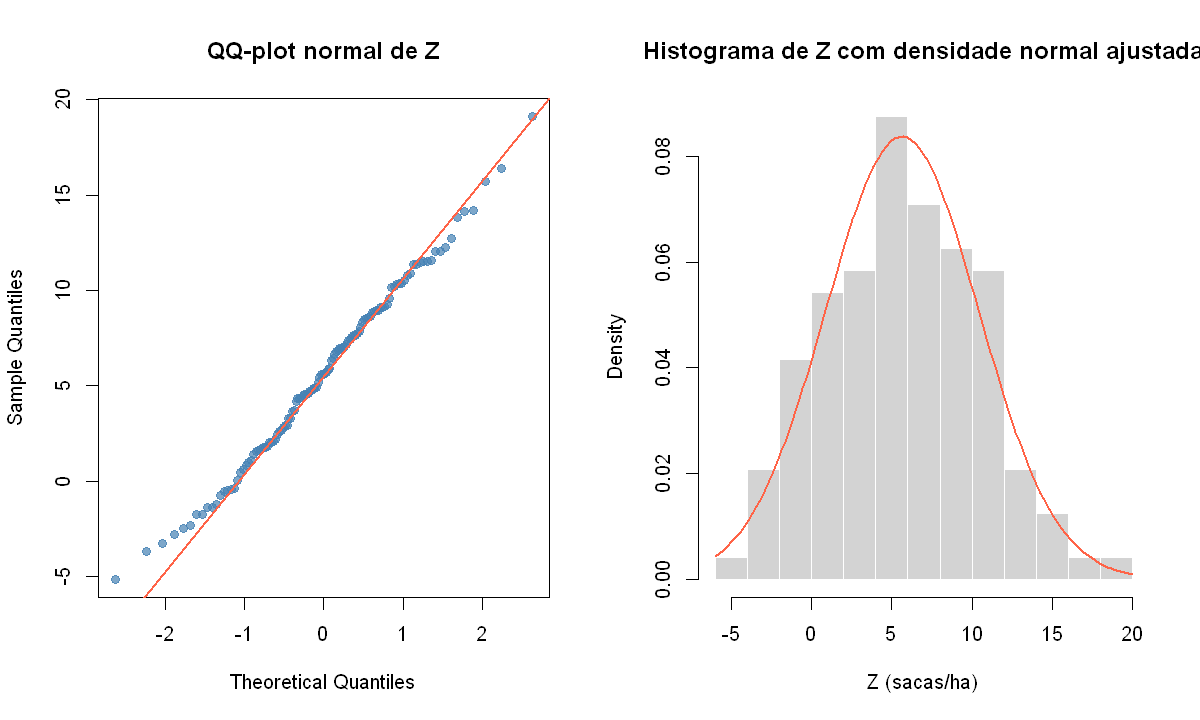

In [18]:
options(repr.plot.width = 10, repr.plot.height = 6)
par(mfrow = c(1, 2))

qqnorm(Z, pch = 19, col = adjustcolor("steelblue", 0.7), main = "QQ-plot normal de Z")
qqline(Z, lwd = 2, col = "tomato")

hist(Z, breaks = 15, freq = FALSE, col = "lightgray", border = "white",
     xlab = "Z (sacas/ha)", main = "Histograma de Z com densidade normal ajustada")
curve(dnorm(x, mean(Z), sd(Z)), add = TRUE, lwd = 2, col = "tomato")

par(mfrow = c(1, 1))

shapiro.test(Z)

Os pontos do QQ-plot ficam praticamente em cima da reta, inclusive nas caudas, e a curva normal ajustada acompanha bem o histograma. O teste de Shapiro-Wilk tem p-valor alto (≈ 0,85), então não há evidência contra a normalidade de $Z$. A suposição (S2) é razoável, e mesmo que não fosse exata, com $n = 120$ o TCL garante que $\bar Z$ é aproximadamente normal.


---

### 7.2 Simetria

Já que até a normalidade foi verificada, nem precisamos a verificação disso mais uma vez.

---

### 7.3 Representatividade dos dados

Temos n = 120 blocos, um tamanho bom da amostra para representar bem a população.

---

### 7.Extra: Independência

Geralmente não tem como provar a independência, pois já vem do delineamento de experimento, e não temos informações sobre localização e ordem de coleta das plantações de milho. Mas se quisermos muito, supondo que número dos blocos sejam a ordem de coleta:


	Box-Ljung test

data:  Z
X-squared = 4.9753, df = 10, p-value = 0.8928


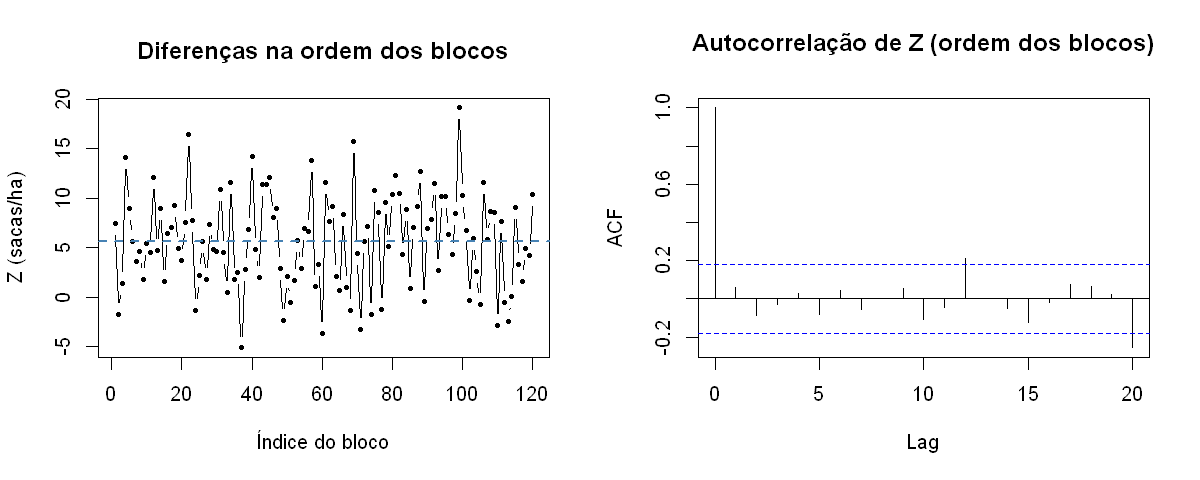

In [19]:
options(repr.plot.width = 10, repr.plot.height = 4)
par(mfrow = c(1, 2))

plot(1:n, Z, type = "b", pch = 19, cex = 0.6,
     xlab = "Índice do bloco", ylab = "Z (sacas/ha)", main = "Diferenças na ordem dos blocos")
abline(h = mean(Z), lty = 2, col = "steelblue", lwd = 2)

acf(Z, main = "Autocorrelação de Z (ordem dos blocos)")

par(mfrow = c(1, 1))

# Teste de Box-Pierce/Ljung-Box para autocorrelação até a defasagem 10
Box.test(Z, lag = 10, type = "Ljung-Box")

Não há evidência contra a independência. Já que o teste de Ljung-Box não rejeita e as diferenças oscilam aleatoriamente em torno de uma média.

---

## 8. Aplicando testes

### 8.1 Método frequentista: teste t pareado

Sob $H_0$ e com a suposição da normalidade:

$$T = \frac{\bar Z - 0}{S_Z / \sqrt{n}} \sim t_{n-1},$$

e o intervalo de confiança de $(1-\alpha)100\%$ para $\mu_Z$ é $\bar Z \pm t_{n-1;\,1-\alpha/2}\,\dfrac{S_Z}{\sqrt{n}}$.

In [20]:
Z_barra <- mean(Z)
s_Z   <- sd(Z)
ep_Z  <- s_Z / sqrt(n)
alpha <- 0.05

T_obs  <- Z_barra / ep_Z
gl     <- n - 1
t_crit <- qt(1 - alpha/2, gl)
p_t    <- 2 * pt(-abs(T_obs), gl)
IC_t   <- Z_barra + c(-1, 1) * t_crit * ep_Z

cat(sprintf("Z_bar = %.4f | S_Z = %.4f | EP = %.4f\n", Z_barra, s_Z, ep_Z))
cat(sprintf("T_obs = %.4f com %d g.l. | valor crítico t(%.3f; %d) = %.4f\n", T_obs, gl, 1 - alpha/2, gl, t_crit))
cat(sprintf("p-valor bilateral = %.3e\n", p_t))
cat(sprintf("IC 95%% para mu_Z: [%.4f ; %.4f]\n\n", IC_t[1], IC_t[2]))

Z_bar = 5.6475 | S_Z = 4.7649 | EP = 0.4350
T_obs = 12.9837 com 119 g.l. | valor crítico t(0.975; 119) = 1.9801
p-valor bilateral = 1.500e-24
IC 95% para mu_Z: [4.7862 ; 6.5088]



In [21]:
# conferindo
teste_t <- t.test(largo$com, largo$sem, paired = TRUE, conf.level = 1 - alpha)
teste_t


	Paired t-test

data:  largo$com and largo$sem
t = 12.984, df = 119, p-value < 2.2e-16
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 4.786217 6.508783
sample estimates:
mean difference 
         5.6475 


A estatística observada ($T_{obs} \approx 12{,}98$) é muito maior que o valor crítico ($\approx 1{,}98$), e o p-valor é praticamente zero (da ordem de $10^{-24}$). Rejeitamos $H_0$ ao nível de 5%. O IC de 95% para $\mu_Z$ vai de aproximadamente 4,79 a 6,51 sacas/ha e não contém o zero.

---


# 9. Conclusões

In [22]:
# ==========================================================
# Salvando as figuras criadas acima na pasta do .ipynb
# (no Jupyter, a pasta de trabalho padrão é a do notebook)
# ==========================================================
pasta <- getwd()

salvar_png <- function(nome, largura, altura, desenho) {
  png(file.path(pasta, nome), width = largura, height = altura, units = "in", res = 150)
  desenho()
  invisible(dev.off())
  cat("Salvo:", file.path(pasta, nome), "\n")
}

# 4.2 Distribuição da produtividade em cada grupo
salvar_png("aded_dist_prod_grupo.png", 20, 10, function() {
  par(mfrow = c(1, 2))
  boxplot(largo$sem, largo$com,
          names = c("Sem biofertilizante", "Com biofertilizante"),
          col = c("tomato", "steelblue"),
          ylab = "Produtividade (sacas/ha)",
          main = "Irrigação reduzida")
  points(c(1, 2), c(mean(largo$sem), mean(largo$com)), pch = 4, cex = 1.5, lwd = 2)
  hist(largo$sem, breaks = 15, col = adjustcolor("tomato", 0.5), border = "black",
       xlim = range(c(largo$sem, largo$com)), ylim = c(0, 25),
       xlab = "Produtividade (sacas/ha)", ylab = "Frequência",
       main = "Histogramas sobrepostos")
  hist(largo$com, breaks = 15, col = adjustcolor("steelblue", 0.5), border = "black", add = TRUE)
  abline(v = c(mean(largo$sem), mean(largo$com)), col = c("tomato", "steelblue"), lwd = 2, lty = 2)
  legend("topright", legend = c("Sem", "Com"), fill = adjustcolor(c("tomato", "steelblue"), 0.5), bty = "n")
  par(mfrow = c(1, 1))
})

# 4.3 Perfis individuais dos blocos
salvar_png("aded_perfis.png", 10, 7, function() {
  plot(NA, xlim = c(0.8, 2.2), ylim = range(c(largo$sem, largo$com)),
       xaxt = "n", xlab = "Biofertilizante (irrigação reduzida)", ylab = "Produtividade (sacas/ha)",
       main = "Perfis individuais dos 120 blocos")
  axis(1, at = c(1, 2), labels = c("Sem", "Com"))
  for (j in 1:n) {
    lines(c(1, 2), c(largo$sem[j], largo$com[j]), col = adjustcolor(cor_perfil[j], alpha.f = .7))
  }
  lines(c(1, 2), c(mean(largo$sem), mean(largo$com)), lwd = 4, type = "b", pch = 19)
  legend("bottomright",
         legend = c("Bloco com Z > 0", "Bloco com Z < 0", "Médias"),
         col = c("steelblue", "tomato", "black"), lwd = c(1, 1, 4), bty = "n")
})

# 4.4 Diagrama de dispersão X1 vs X2
salvar_png("aded_dispersao.png", 7, 7, function() {
  lim <- range(c(largo$sem, largo$com))
  plot(largo$sem, largo$com, pch = 19, col = adjustcolor(cor_perfil, .7),
       xlim = lim, ylim = lim,
       xlab = "Sem biofertilizante, X1 (sacas/ha)",
       ylab = "Com biofertilizante, X2 (sacas/ha)",
       main = sprintf("Produtividade pareada por bloco (r = %.2f)", r_12))
  abline(0, 1, lty = 2, lwd = 2)
  legend("topleft", legend = c("Reta X2 = X1 (sem efeito)"), lty = 2, lwd = 2, bty = "n")
})

# 4.5 Distribuição das diferenças Z
salvar_png("aded_dist_dif.png", 10, 6, function() {
  par(mfrow = c(1, 2))
  hist(Z, breaks = 15, freq = FALSE, col = "lightgray", border = "white", ylim = c(0, 0.11),
       xlab = "Z = com - sem (sacas/ha)", ylab = "Densidade",
       main = "Histograma das diferenças")
  abline(v = 0, lty = 2, lwd = 2, col = "tomato")
  abline(v = mean(Z), lwd = 2)
  legend("topright", legend = c( "Z = 0", "Média de Z"),
         col = c( "tomato", "black"), lty = c(2, 1), lwd = 2, bty = "n", cex = 0.75)
  boxplot(Z, horizontal = TRUE, col = "lightgray",
          xlab = "Z = com - sem (sacas/ha)", main = "Boxplot das diferenças")
  abline(v = 0, lty = 2, lwd = 2, col = "tomato")
  points(mean(Z), 1, pch = 4, cex = 1.5, lwd = 2)
  par(mfrow = c(1, 1))
})

# 7.1 Normalidade
salvar_png("sup_normalidade.png", 10, 6, function() {
  par(mfrow = c(1, 2))
  qqnorm(Z, pch = 19, col = adjustcolor("steelblue", 0.7), main = "QQ-plot normal de Z")
  qqline(Z, lwd = 2, col = "tomato")
  hist(Z, breaks = 15, freq = FALSE, col = "lightgray", border = "white",
       xlab = "Z (sacas/ha)", main = "Histograma de Z com densidade normal ajustada")
  curve(dnorm(x, mean(Z), sd(Z)), add = TRUE, lwd = 2, col = "tomato")
  par(mfrow = c(1, 1))
})

# 7.Extra Independência
salvar_png("sup_independencia.png", 10, 4, function() {
  par(mfrow = c(1, 2))
  plot(1:n, Z, type = "b", pch = 19, cex = 0.6,
       xlab = "Índice do bloco", ylab = "Z (sacas/ha)", main = "Diferenças na ordem dos blocos")
  abline(h = mean(Z), lty = 2, col = "steelblue", lwd = 2)
  acf(Z, main = "Autocorrelação de Z (ordem dos blocos)")
  par(mfrow = c(1, 1))
})

Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/aded_dist_prod_grupo.png 
Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/aded_perfis.png 
Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/aded_dispersao.png 
Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/aded_dist_dif.png 
Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/sup_normalidade.png 
Salvo: c:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MCI/Trabalho 1/sup_independencia.png 
